# Assignment 4 - One- and Two-Sample Tests

Group members: Sebastian Bartko, Mariia Moskovko, Matej Palas, Sebastian Halas

Table of contents
1. Part 1 - One-sample decisions
2. Part 2 - Independent coating processes
3. Part 3 - Paired building-energy measurements
4. Part 4 - Comparing two independent proportions
5. Part 5 - AI-use and conclusion

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportion_confint

In [5]:
sensors = pd.read_csv("data/assignment03_sensor_calibration.csv")
access = pd.read_csv("data/assignment03_access_control.csv")
coating = pd.read_csv("data/assignment04_coating_durability.csv")
energy = pd.read_csv("data/assignment04_energy_retrofit.csv")

display(sensors.head())
display(access.head())
display(coating.head())
display(energy.head())

,sensor_id,calibration_error_c
0,1,0.334
1,2,0.383
2,3,1.644
3,4,0.627
4,5,0.615


,attempt_id,false_reject
0,1,0
1,2,0
2,3,0
3,4,1
4,5,0


,specimen_id,process,durability_h
0,1,standard,112.45
1,2,standard,109.55
2,3,standard,131.35
3,4,standard,130.96
4,5,standard,110.15


,building_id,before_kwh_day,after_kwh_day
0,1,91.57,87.75
1,2,95.33,90.14
2,3,85.20,85.61
3,4,75.96,64.30
4,5,85.33,81.90


# Part 1 - One-sample decisions

## Mean sensor error

Use assignment03_sensor_calibration.csv. The engineering team asks whether population mean calibration error differs from zero; errors with absolute mean below $0.50\ ^\circ\mathrm{C}$ are regarded as small in practice.

**a.** State $H_0$, the two-sided $H_1$, and $\alpha = 0.05$. Use a one-sample $t$ procedure and report the sample mean, test statistic, degrees of freedom, and two-sided $p$-value.

In [3]:
# TODO

*TODO: answer*

**b.** Interpret the $p$-value as a tail probability conditional on $H_0$ and the assumptions. State the decision and a contextual conclusion without treating the $p$-value as $P(H_0 \mid \text{data})$.

*TODO: answer*

**c.** Reuse or reconstruct the 95% $t$ interval and explain its duality with this two-sided test. Compare it with the practical limits and distinguish statistical significance from practical importance.

In [4]:
# TODO

*TODO: answer*

## False-rejection probability

Use assignment03_access_control.csv. The pre-specified question is whether the false-rejection probability exceeds the 5% target.

**a.** State the one-sided hypotheses. Perform an exact binomial test and report $\hat{p}$, the $p$-value, decision, and conclusion.

In [5]:
# TODO

*TODO: answer*

**b.** Use the Wilson interval as an estimate of plausible values, while explaining why a two-sided Wilson interval is not the exact dual of a one-sided exact test.

In [6]:
# TODO

*TODO: answer*

**c.** Describe Type I and Type II errors in one of the two one-sample studies and state an operational consequence of each.

*TODO: answer*

# Part 2 - Independent coating processes

The file assignment04_coating_durability.csv contains independent specimens from a standard and modified coating process. Let

$$\delta = \mu_{\text{modified}} - \mu_{\text{standard}},$$

measured in durability hours. An increase of at least 8 hours is considered practically important.

Complete the following tasks:

**a.** Explain why the samples are independent rather than paired. Report group $n$, mean, sample standard deviation, and boxplots.

['specimen_id', 'process', 'durability_h']
   specimen_id   process  durability_h
0            1  standard        112.45
1            2  standard        109.55
2            3  standard        131.35
3            4  standard        130.96
4            5  standard        110.15
using y_col = durability_h
process
modified    48
standard    44
Name: count, dtype: int64
n standard = 44, n modified = 48
           n    mean     sd
process                    
modified  48  132.49  22.19
standard  44  117.29  15.75


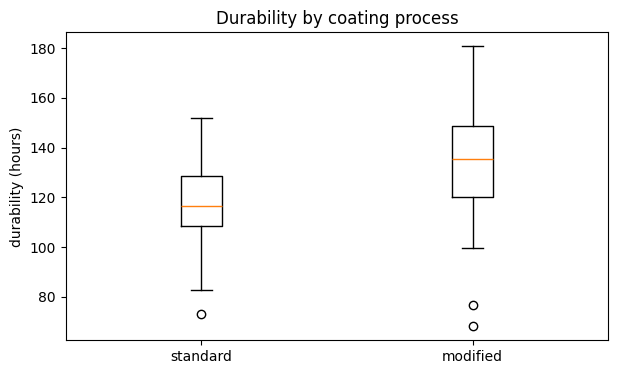

In [7]:
print(coating.columns.tolist())
print(coating.head())

group_col = "process"
y_col = [c for c in coating.columns if "dur" in c.lower() or "hour" in c.lower()][0]
print("using y_col =", y_col)
print(coating[group_col].value_counts())

standard = coating.loc[coating[group_col].str.lower() == "standard", y_col]
modified = coating.loc[coating[group_col].str.lower() == "modified", y_col]
print(f"n standard = {len(standard)}, n modified = {len(modified)}")

summary = coating.groupby(group_col)[y_col].agg(n="count", mean="mean", sd="std")
print(summary.round(2))

fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot([standard, modified])
ax.set_xticks([1, 2], ["standard", "modified"])
ax.set_ylabel("durability (hours)")
ax.set_title("Durability by coating process")
plt.show()

The observational unit is one specimen. Each specimen got only one coating process, so the standard group and the modified group contain different specimens. No specimen was measured twice and no specimen in one group has a natural partner in the other group. The groups even have different sizes (44 and 48), so the rows could not be matched one to one. That is why the samples are independent and not paired. The design decides this, not the spreadsheet. If we sorted the two columns and matched them row by row, it would still not be a paired design.

| process  | n  | mean (h) | SD (h) |
|----------|----|----------|--------|
| standard | 44 | 117.29   | 15.75  |
| modified | 48 | 132.49   | 22.19  |

The modified process has the higher mean, about 132.49 − 117.29 = 15.20 hours more than the standard process. In the boxplots the whole modified box is shifted up: its median is about 135 h against about 117 h for the standard process. The boxes still overlap a little (roughly 120 to 128 h), so some standard specimens last longer than some modified ones. The spread is larger in the modified group (SD 22.19 h against 15.75 h, and longer whiskers), so the two groups do not have the same variance. This is one more reason to use Welch's procedure, which does not assume equal variances.

Both groups have a few low values marked as points: one in the standard group (about 73 h) and two in the modified group (about 68 and 77 h). In the modified group these low values pull the mean (132.49 h) a bit below the median (about 135 h). We look at these values again in part c.

**b.** State two-sided hypotheses about $\delta$. Use Welch's two-sample $t$ procedure and report the estimated difference, 95% confidence interval, statistic, approximate degrees of freedom, and $p$-value. Do not use a preliminary variance test to switch automatically between pooled and Welch procedures.

In [8]:
# Welch two-sample t, order fixed before looking at the data: delta = modified - standard
welch = stats.ttest_ind(modified, standard, equal_var=False)
welch_ci = welch.confidence_interval(0.95)

n1, n2 = len(modified), len(standard)
s1, s2 = modified.std(), standard.std()
diff = modified.mean() - standard.mean()
se = np.sqrt(s1**2 / n1 + s2**2 / n2)
nu = (s1**2 / n1 + s2**2 / n2)**2 / ((s1**2 / n1)**2 / (n1 - 1) + (s2**2 / n2)**2 / (n2 - 1))

print(f"estimated difference = {diff:.2f} h")
print(f"SE = {se:.2f} h")
print(f"t = {welch.statistic:.2f}, df = {welch.df:.2f} (by hand: {nu:.2f}), p-value = {welch.pvalue:.2g}")
print(f"95% CI for delta = ({welch_ci.low:.2f}, {welch_ci.high:.2f}) h")

estimated difference = 15.20 h
SE = 3.99 h
t = 3.81, df = 84.84 (by hand: 84.84), p-value = 0.00026
95% CI for delta = (7.27, 23.13) h


H0: δ = 0 (no difference in mean durability). H1: δ ≠ 0. We use α = 0.05.

We use Welch's test because the groups are independent and it does not assume that the two population variances are equal. We decided to use Welch before looking at the data, so we do not run a variance pre-test and switch to the pooled test. The order δ = μ_modified − μ_standard was also fixed in advance, so a positive value means the modified coating lasts longer.

The estimated difference is 132.49 − 117.29 = 15.20 h. The standard error is SE = √(22.19²/48 + 15.75²/44) = 3.99 h, so t = 15.20 / 3.99 = 3.81. The Welch formula gives approximately 84.84 degrees of freedom; the value from scipy and our own calculation agree. If the true mean difference were 0 and the assumptions hold, a t value this far from 0 would be very unlikely (p ≈ 0.00026). Since p < 0.05 we reject H0. The data give strong evidence that the mean durability is different, and the modified process lasts longer.

The 95% CI for δ is (7.27, 23.13) h. It does not include 0, which matches the test result. The interval is quite wide, so the true gain could be anywhere from about 7 h to about 23 h.

**c.** Assess independence from the design and distribution shape and unusual observations from group plots or residual diagnostics. State what the plots cannot establish.

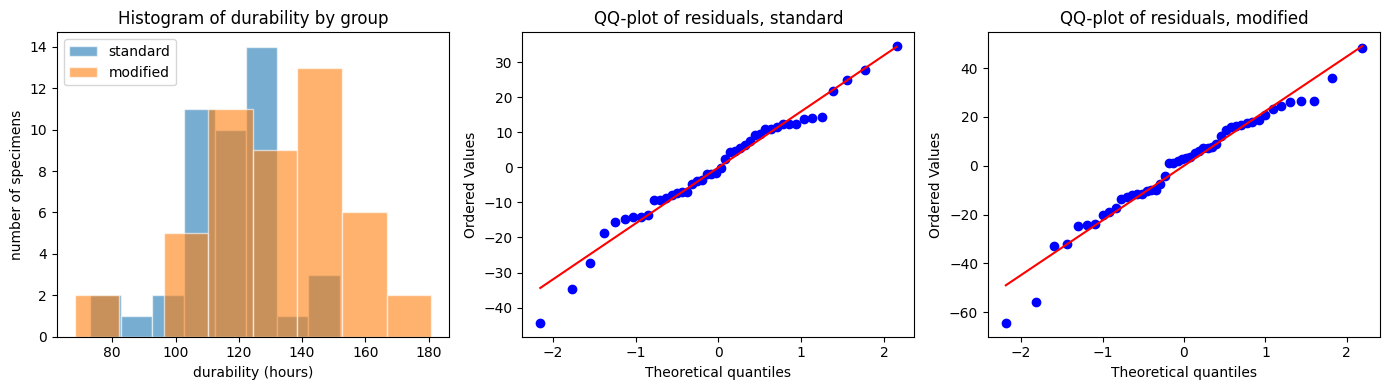

standard: mean = 117.29, median = 116.37, min = 72.93, max = 151.87, outliers (1.5 IQR) = [72.93]
modified: mean = 132.49, median = 135.36, min = 68.12, max = 180.77, outliers (1.5 IQR) = [76.48, 68.12]


In [9]:
coating["resid"] = coating[y_col] - coating.groupby(group_col)[y_col].transform("mean")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].hist(standard, bins=8, alpha=0.6, edgecolor="white", label="standard")
axes[0].hist(modified, bins=8, alpha=0.6, edgecolor="white", label="modified")
axes[0].set_title("Histogram of durability by group")
axes[0].set_xlabel("durability (hours)")
axes[0].set_ylabel("number of specimens")
axes[0].legend()

stats.probplot(standard - standard.mean(), plot=axes[1])
axes[1].set_title("QQ-plot of residuals, standard")

stats.probplot(modified - modified.mean(), plot=axes[2])
axes[2].set_title("QQ-plot of residuals, modified")

plt.tight_layout()
plt.show()

for name, x in [("standard", standard), ("modified", modified)]:
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    out = x[(x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)]
    print(f"{name}: mean = {x.mean():.2f}, median = {x.median():.2f}, min = {x.min():.2f}, "
          f"max = {x.max():.2f}, outliers (1.5 IQR) = {out.round(2).tolist()}")

Independence comes from the design and not from the plots. Each specimen was coated once with one process, so the two groups are separate specimens, and the different group sizes (44 and 48) show that there is no pairing. Inside each group the specimens should also not influence each other. We cannot check this from the data. For example, specimens from the same batch, the same oven run or the same test day could be related, and we would need to know more about how the study was set up.

The histograms are roughly bell-shaped in both groups. The standard group is centred around 110–130 h and the modified group around 130–150 h, so the whole modified distribution is shifted up and is also wider. Both groups have a short tail of low values. The modified group is slightly left-skewed (median 135.36 h, mean 132.49 h), while the standard group is close to symmetric (median 116.37 h, mean 117.29 h).

In the QQ-plots of the residuals the points stay close to the line in the middle and at the upper end. At the lower end a few points fall below the line in both groups, which means the lower tail is a bit longer than for a normal distribution. These are the same low values that the 1.5 IQR rule marks as outliers: 72.93 h in the standard group and 76.48 h and 68.12 h in the modified group. They are only 3 of 92 specimens, they are not extremely far from the rest, and we have no reason to think they are measurement errors, so we keep them. They also do not create the difference: removing them would raise the modified mean more than the standard mean (from 15.20 h to about 16.8 h), so the estimate would get larger, not smaller.

With only a mild lower tail and 44 + 48 specimens, the Welch t procedure looks reasonable, because the sample means are close to normal by the central limit theorem. The different spreads are no problem because Welch does not need equal variances.

The plots cannot show that the specimens are independent, and they cannot prove that the populations are normal. They can only fail to show a clear problem. They also cannot show that the coating process caused the difference. That depends on whether the specimens were randomly assigned to the processes. Finally, they cannot explain why the few low values happened.

**d.** Compare the interval with both zero and the 8-hour practical threshold. Give a recommendation that reflects statistical uncertainty and practical importance.

The 95% CI for δ is (7.27, 23.13) h. We compare it with two values: 0 (no difference) and 8 h (the smallest increase that is practically important).

The interval is far above 0, so the data give strong evidence that the modified process lasts longer than the standard process (p ≈ 0.00026). The estimated gain is 15.20 h, almost twice the 8-hour threshold, and most of the interval lies above 8 h. But the lower end, 7.27 h, is just below 8 h. So a gain slightly smaller than the practically important amount is still plausible, and we cannot say with 95% confidence that the gain is at least 8 h.

Statistical significance only tells us that δ is probably not 0. The practical question is whether δ is at least 8 h, and for that we have to look at where the whole interval lies, not only at the p-value.

Our recommendation is that the modified process looks promising and is likely to give a practically important gain, but this study alone does not quite prove it. If switching is cheap, it is reasonable to switch, because even the worst plausible case (about 7.3 h) is close to the threshold and there is no sign that the modified process is worse. If switching is expensive, a confirmation study with more specimens would give a narrower interval and could show whether the whole interval lies above 8 h. We do not have cost data, so the data alone cannot decide this. Before a wider rollout it would also be good to check that the specimens were randomly assigned to the processes. The modified process also has a larger spread and a few low values, so some specimens may still last less than with the standard process.

# Part 3 - Paired building-energy measurements

The file assignment04_energy_retrofit.csv records energy use for the same 36 buildings before and after a control-system retrofit. Define the paired difference

$$D = \text{before} - \text{after},$$

so a positive value represents a reduction.

Complete the following tasks:

**a.** Explain the observational unit and why the rows form genuine pairs. Create the difference column and report its mean, standard deviation, and standard error.

In [10]:
energy["D"] = energy["before_kwh_day"] - energy["after_kwh_day"]
D = energy["D"]

n = len(D)
mean_D = D.mean()
sd_D = D.std()
se_D = sd_D / np.sqrt(n)

print(f"n = {n}")
print(f"mean of D = {mean_D:.2f} kWh/day")
print(f"SD of D   = {sd_D:.2f} kWh/day")
print(f"SE of D   = {se_D:.2f} kWh/day")

n = 36
mean of D = 4.82 kWh/day
SD of D   = 4.50 kWh/day
SE of D   = 0.75 kWh/day


The observational unit is one building. Each row is one building measured twice, once before and once after the retrofit.

The rows are genuine pairs because both values in a row come from the same building (same building_id). A building keeps its size and its type of use, so these do not change much between the two measurements. The pairing comes from how the study was set up, we did not match the values afterwards.

The mean difference is 4.82 kWh/day, the SD is 4.50 kWh/day and the SE is 4.50/√36 = 0.75 kWh/day. So on average the buildings used about 4.8 kWh/day less after the retrofit.

**b.** Plot the paired values and the distribution or QQ-plot of differences. Diagnose the differences—not the two raw columns separately—for the paired $t$ procedure.

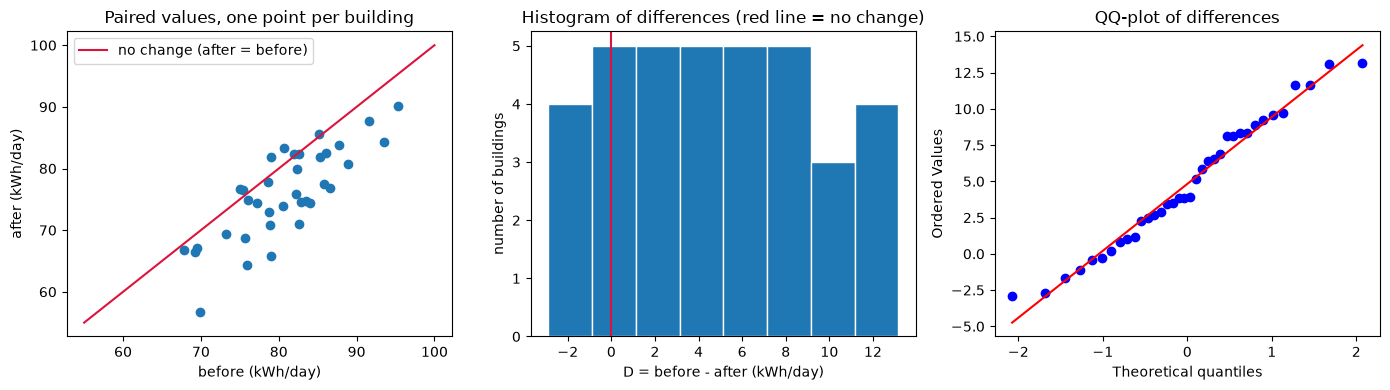

buildings with lower use after: 30 of 36
mean = 4.82, median = 3.90, min = -2.90, max = 13.17


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].scatter(energy["before_kwh_day"], energy["after_kwh_day"])
axes[0].plot([55, 100], [55, 100], color="crimson", label="no change (after = before)")
axes[0].set_title("Paired values, one point per building")
axes[0].set_xlabel("before (kWh/day)")
axes[0].set_ylabel("after (kWh/day)")
axes[0].legend()

axes[1].hist(D, bins=8, edgecolor="white")
axes[1].axvline(0, color="crimson")
axes[1].set_title("Histogram of differences (red line = no change)")
axes[1].set_xlabel("D = before - after (kWh/day)")
axes[1].set_ylabel("number of buildings")

stats.probplot(D, plot=axes[2])
axes[2].set_title("QQ-plot of differences")

plt.tight_layout()
plt.show()

print(f"buildings with lower use after: {(D > 0).sum()} of {n}")
print(f"mean = {mean_D:.2f}, median = {D.median():.2f}, min = {D.min():.2f}, max = {D.max():.2f}")

In the left plot most points are below the red line, which means lower energy use after the retrofit. 30 of the 36 buildings went down and 6 went up.

The paired t procedure only uses the differences, so we check those and not the two raw columns. The histogram is quite flat and not a clear bell shape, but it has no strong skew (mean 4.82, median 3.90) and only 36 points, so its shape is rough anyway. In the QQ-plot the points stay close to the line, with only small gaps at the two ends. There are no outliers. The building that looks far from the others in the left plot (building 20) has one of the largest differences (about 13 kWh/day), but this value still fits the line in the QQ-plot.

With no big problem in the shape and n = 36, the paired t procedure looks reasonable. The plots cannot show if the buildings are independent of each other. For example, buildings with the same owner or in the same area could be related, and we would need to know more about the study to check this.

**c.** Test $H_0: \mu_D = 0$ against a two-sided alternative and construct a 95% interval for $\mu_D$, using `ttest_rel` or an equivalent one-sample procedure applied to the differences.

In [12]:
paired = stats.ttest_rel(energy["before_kwh_day"], energy["after_kwh_day"])
paired_ci = paired.confidence_interval(0.95)

print(f"t = {paired.statistic:.2f}, df = {paired.df}, p-value = {paired.pvalue:.2g}")
print(f"95% CI for mean D = ({paired_ci.low:.2f}, {paired_ci.high:.2f}) kWh/day")

t = 6.43, df = 35, p-value = 2.1e-07
95% CI for mean D = (3.30, 6.35) kWh/day


H0: μD = 0 (no change in mean energy use). H1: μD ≠ 0. We use α = 0.05.

We get t = 6.43 with df = 35 and p ≈ 2.1e-07. If the true mean difference was 0 and the assumptions hold, a t value this far from 0 would almost never happen, so we reject H0. The data give strong evidence that mean energy use changed, and the change is a reduction.

The 95% CI for μD is (3.30, 6.35) kWh/day. It does not include 0, which matches the test result.

**d.** Explain why an independent-samples test would discard useful pairing. Interpret the estimated reduction and interval in kWh/day and state a practical recommendation.

In [13]:
# Only to compare with the paired result, not a valid test for this data
indep = stats.ttest_ind(energy["before_kwh_day"], energy["after_kwh_day"], equal_var=False)
indep_ci = indep.confidence_interval(0.95)
se_indep = mean_D / indep.statistic

print(f"correlation of before and after = {energy['before_kwh_day'].corr(energy['after_kwh_day']):.2f}")
print(f"SE paired = {se_D:.2f}, SE independent = {se_indep:.2f}")
print(f"95% CI paired      = ({paired_ci.low:.2f}, {paired_ci.high:.2f}), width {paired_ci.high - paired_ci.low:.2f}")
print(f"95% CI independent = ({indep_ci.low:.2f}, {indep_ci.high:.2f}), width {indep_ci.high - indep_ci.low:.2f}")
print(f"mean before = {energy['before_kwh_day'].mean():.2f} kWh/day")
print(f"reduction in percent: {mean_D / energy['before_kwh_day'].mean():.1%}")

correlation of before and after = 0.80
SE paired = 0.75, SE independent = 1.65
95% CI paired      = (3.30, 6.35), width 3.05
95% CI independent = (1.53, 8.12), width 6.58
mean before = 80.78 kWh/day
reduction in percent: 6.0%


An independent-samples test would treat the before and after values as two separate groups of buildings. But they are the same buildings, and the two columns are strongly related (correlation 0.80), so that test's assumption is not true here. It would also count the normal differences between big and small energy users as noise. Pairing removes these differences because each building is compared with itself. This is why the SE is 0.75 for the paired test and 1.65 for the independent test, and the CI is much narrower (width 3.05 against 6.58 kWh/day).

We estimate that the retrofit is linked to a mean reduction of 4.82 kWh/day per building, and values from 3.30 to 6.35 kWh/day are plausible. That is about 6% of the mean use before the retrofit (roughly 4% to 8%). Over a year it is about 1,760 kWh per building (roughly 1,200 to 2,300 kWh).

Our recommendation is to continue with the retrofit if the cost is justified by savings at the low end of the interval, about 3.3 kWh/day. We do not have cost data, so the data alone cannot decide this. There is also no control group. Weather or building use could have changed between the two periods, so we cannot be sure that the retrofit caused the whole reduction. Also, 6 buildings went up, so it would be good to check those before a wider rollout.

# Part 4 - Comparing two independent proportions

Two independently assigned software configurations were evaluated using separate requests. Configuration A had 38 SLA failures among 300 requests; configuration B had 22 among 320. Define the risk difference as $p_A - p_B$.

Complete the following tasks:

**a.** State the observational unit, binary outcome, populations, assumptions, comparison order, and two-sided hypotheses.

*TODO: answer*

**b.** Calculate both sample proportions, their difference in percentage points, and a 95% confidence interval using separate estimated variances.

In [14]:
# TODO

*TODO: answer*

**c.** Test $H_0: p_A = p_B$ with a two-proportion $z$ procedure. Report $z$, the two-sided $p$-value, decision, and contextual conclusion.

In [15]:
# TODO

*TODO: answer*

**d.** State what random sampling and random assignment would each support and why a significant difference alone is not enough for an unrestricted causal claim.

*TODO: answer*

# Part 5 - AI-use and conclusion

## AI-use

State which AI tools you used, what they contributed, what you changed or rejected, and how you verified the final work. A short paragraph or table is sufficient.

(Mofo--)  
* Helped create the plots
* compared statements against generated statements
* formulated statements using AI

## Overall conclusion

Write approximately 150–250 words comparing what the four designs allow you to conclude. Include effects and intervals, not only decisions, and distinguish statistical significance, practical importance, and causal interpretation.

Only use Sessions 7–8. Do not use ANOVA, regression, or chi-square methods.

*TODO: answer*